# SecondLook | 08 Fairness audit

**Goal:** check whether good borrowers are treated equally across **gender**, **age** and **thin credit files**, say how sure we are, and test one fix, so we can defend the model's limits.

**Why this matters for SecondLook:** the project exists for applicants a lender can't read, so a model that quietly turns away good young or thin-file borrowers would defeat the point. Gender is **not** a model input, but other features can stand in for it (proxies). Age **is** an input.

**What we measure, per group** (`src/secondlook/fairness.py`), on all **61,503 test applicants** the model never saw, at the shipped cutoff (approve if PD < 0.17):

| Metric | Question it answers |
|---|---|
| Approval rate | How often is the group approved? |
| Default rate | How risky is the group really? (the base rate) |
| Approval rate of repayers | Of the people who **did** repay, how many did we approve? (*equal opportunity*) |
| Decline rate of repayers | Good borrowers we turned away (1 minus the above) |
| Default rate of approved | Do approved loans in this group default more often? |
| Mean predicted PD vs actual | *Calibration*: does the model over- or under-state the group's risk? |
| Four-fifths ratio | Group approval rate ÷ best group's. Under 0.8 is the usual red flag (a rule of thumb from US hiring law, used widely in lending audits) |

Then we **bootstrap** the gaps (1,000 resamples) to get 95% intervals, and **retrain** the model without the sensitive features to see whether that narrows the gaps.

## 1. Setup

In [1]:
import json
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "secondlook").exists())
sys.path.insert(0, str(ROOT / "src"))

from secondlook import fairness as F
from secondlook.config import FIGURES_DIR, PROCESSED_DIR
from secondlook.modeling import load_model

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
GROUPINGS = ["Gender", "Age band", "Credit file"]

def save(fig, name):
    fig.savefig(FIGURES_DIR / f"{name}.png", bbox_inches="tight")

## 2. The test applicants and the groups

The test predictions were saved in notebook 03. Age bands use whole years (20-29 means 20 up to, but not including, 30). *Thin file* means no record at any credit bureau. Two applicants with unknown gender are left out of the gender tables (groups under 100 people give unreliable rates).

In [2]:
_, meta = load_model()
CUTOFF = meta["cutoff"]
df = F.add_groups(pd.read_parquet(PROCESSED_DIR / "test_predictions.parquet"))
print(f"{len(df):,} test applicants, {df['TARGET'].mean():.1%} defaulted, cutoff PD < {CUTOFF}")
print(f"Overall approval rate: {(df['PD_LGBM'] < CUTOFF).mean():.1%}   (model card: {meta['metrics']['approval_rate']:.1%})")
for g in GROUPINGS:
    print(f"\n{g}: " + ", ".join(f"{k} {v:,}" for k, v in df[g].value_counts(dropna=False, sort=False).items()))

61,503 test applicants, 8.1% defaulted, cutoff PD < 0.17
Overall approval rate: 88.2%   (model card: 88.2%)

Gender: Male 20,940, Female 40,561, nan 2

Age band: 20-29 8,905, 30-39 16,487, 40-49 15,303, 50-59 13,617, 60-69 7,191

Credit file: Bureau history 52,727, Thin file 8,776


## 3. Every metric, per group

In [3]:
PCT = ["Default rate", "Approval rate", "Approval rate of repayers", "Decline rate of repayers",
       "Default rate of approved", "Mean predicted PD"]
fmt = {**{c: "{:.1%}" for c in PCT}, "Applicants": "{:,}", "Calibration gap": "{:+.1%}", "Four-fifths ratio": "{:.2f}"}
tables = {g: F.group_table(df, g, cutoff=CUTOFF) for g in GROUPINGS}
for g in GROUPINGS:
    display(tables[g].style.format(fmt).set_caption(g))

,Applicants,Default rate,Approval rate,Approval rate of repayers,Decline rate of repayers,Default rate of approved,Mean predicted PD,Calibration gap,Four-fifths ratio,Below 0.8
Gender,,,,,,,,,,
Female,"40,561",7.0%,90.1%,92.2%,7.8%,4.8%,7.2%,+0.2%,1.00,False
Male,"20,940",10.2%,84.4%,88.1%,11.9%,6.3%,9.3%,-0.9%,0.94,False


,Applicants,Default rate,Approval rate,Approval rate of repayers,Decline rate of repayers,Default rate of approved,Mean predicted PD,Calibration gap,Four-fifths ratio,Below 0.8
Age band,,,,,,,,,,
20-29,"8,905",11.3%,79.2%,83.1%,16.9%,6.9%,11.3%,-0.0%,0.82,False
30-39,"16,487",9.6%,84.2%,87.6%,12.4%,5.9%,9.4%,-0.2%,0.87,False
40-49,"15,303",7.6%,89.3%,91.8%,8.2%,5.0%,7.5%,-0.0%,0.93,False
50-59,"13,617",6.3%,93.3%,94.9%,5.1%,4.8%,6.1%,-0.3%,0.97,False
60-69,"7,191",5.0%,96.4%,97.2%,2.8%,4.2%,4.8%,-0.2%,1.00,False


,Applicants,Default rate,Approval rate,Approval rate of repayers,Decline rate of repayers,Default rate of approved,Mean predicted PD,Calibration gap,Four-fifths ratio,Below 0.8
Credit file,,,,,,,,,,
Bureau history,"52,727",7.7%,89.1%,91.6%,8.4%,5.2%,7.6%,-0.1%,1.00,False
Thin file,"8,776",10.1%,82.7%,86.2%,13.8%,6.3%,10.0%,-0.1%,0.93,False


**What the tables show**

- **Approval rates follow real risk.** Men default more often than women (10.2% vs 7.0%), young applicants more than older ones (11.3% for 20-29 vs 5.0% for 60-69), and thin files more than applicants with a bureau record (10.1% vs 7.7%). Approval rates are lower in exactly those groups.
- **The model is well calibrated in every group.** Mean predicted PD is within about 1 point of the actual default rate everywhere (the largest gap is men, where the model *under*states risk by 0.9 points). So the model is not inflating anyone's risk: one cutoff means the same risk for everyone.
- **But good borrowers are not approved equally.** Among applicants who repaid, 97.2% of 60-69 year olds were approved but only 83.1% of 20-29 year olds; 92.2% of women vs 88.1% of men; 91.6% with a bureau record vs 86.2% of thin files. A good young borrower is about **six times** as likely to be turned away as a good older one (16.9% vs 2.8%).
- **Approved loans in the disfavoured groups still default more** (6.9% for 20-29 vs 4.2% for 60-69). So the model is not being *harsher* on young applicants than their risk warrants. If anything the cutoff lets more risk through for them.

This is the well-known conflict between fairness definitions: when two groups have different real default rates, a model can't be calibrated for both **and** give their repayers equal approval rates at the same time. A single cutoff on a calibrated score treats equal risk equally, and that leaves the equal-opportunity gap.

## 4. The four-fifths check

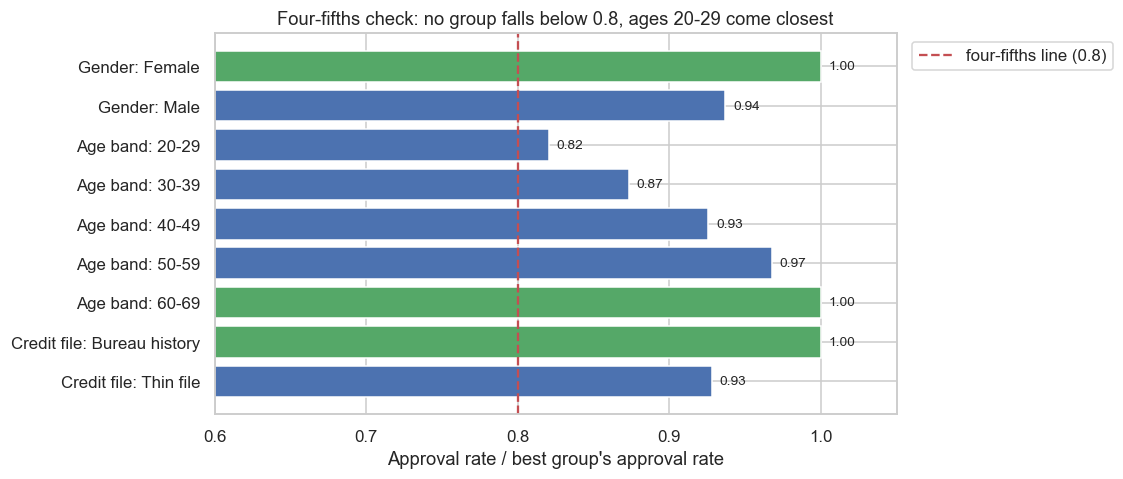

In [4]:
ratios = pd.concat([t["Four-fifths ratio"].rename(lambda k, g=g: f"{g}: {k}") for g, t in tables.items()])
fig, ax = plt.subplots(figsize=(8, 4.5))
colors = ["#C44E52" if r < F.FOUR_FIFTHS else "#55A868" if r == 1 else "#4C72B0" for r in ratios]
ax.barh(ratios.index[::-1], ratios.values[::-1], color=colors[::-1])
ax.axvline(F.FOUR_FIFTHS, color="#C44E52", ls="--", lw=1.5, label="four-fifths line (0.8)")
for i, r in enumerate(ratios.values[::-1]):
    ax.text(r + 0.005, i, f"{r:.2f}", va="center", fontsize=9)
ax.set(xlim=(0.6, 1.05), xlabel="Approval rate / best group's approval rate",
       title="Four-fifths check: no group falls below 0.8, ages 20-29 come closest")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
save(fig, "28_four_fifths")
plt.show()

**No group falls below 0.8.** The youngest band comes closest at **0.82**, then 30-39 at 0.87. Gender (0.94) and thin files (0.93) are well clear. Passing the rule of thumb doesn't make the age gap acceptable on its own, so the next sections test whether it's real and whether it can be reduced.

## 5. Are the gaps real? Bootstrap intervals

For each grouping we compare the group with the highest approval rate against the lowest, resample the test applicants 1,000 times with replacement, and recompute every gap. The middle 95% of the resampled gaps is the interval. If it excludes zero (or 1.0 for the ratio), the gap is not sampling noise.

In [5]:
gaps = pd.concat([F.bootstrap_gaps(df, g, cutoff=CUTOFF, n_boot=1000) for g in GROUPINGS], ignore_index=True)
show = gaps.copy()
pp = show["Metric"] != "Four-fifths ratio"
for c in ["Gap", "95% CI low", "95% CI high"]:
    show[c] = np.where(pp, (show[c] * 100).map("{:+.1f} pts".format), show[c].map("{:.3f}".format))
show

,Grouping,Comparison,Metric,Gap,95% CI low,95% CI high,Real (CI excludes no gap)
0,Gender,Female vs Male,Approval rate,+5.7 pts,+5.1 pts,+6.2 pts,True
1,Gender,Female vs Male,Approval rate of repayers,+4.2 pts,+3.6 pts,+4.7 pts,True
2,Gender,Female vs Male,Default rate of approved,-1.5 pts,-1.9 pts,-1.1 pts,True
3,Gender,Female vs Male,Four-fifths ratio,0.937,0.931,0.943,True
4,Age band,60-69 vs 20-29,Approval rate,+17.3 pts,+16.4 pts,+18.3 pts,True
5,Age band,60-69 vs 20-29,Approval rate of repayers,+14.1 pts,+13.2 pts,+15.0 pts,True
6,Age band,60-69 vs 20-29,Default rate of approved,-2.7 pts,-3.4 pts,-1.9 pts,True
7,Age band,60-69 vs 20-29,Four-fifths ratio,0.821,0.811,0.830,True
8,Credit file,Bureau history vs Thin file,Approval rate,+6.4 pts,+5.6 pts,+7.2 pts,True
9,Credit file,Bureau history vs Thin file,Approval rate of repayers,+5.3 pts,+4.6 pts,+6.1 pts,True


**All twelve gaps are real.** Every interval excludes "no gap", and most are narrow because the groups are large:

- **Age:** repayers aged 60-69 are approved **14.1 points** more often than repayers aged 20-29 (95% interval 13.2 to 15.0). The four-fifths ratio is 0.82 with an interval of 0.81 to 0.83, so the youngest band is close to, but reliably above, the 0.8 line.
- **Gender:** women who repaid are approved **4.2 points** more often than men who repaid (3.6 to 4.7).
- **Thin file:** repayers with a bureau record are approved **5.3 points** more often than thin-file repayers (4.6 to 6.1). This is the gap SecondLook was built for.
- The **default rate of approved** gaps are negative in every grouping: approved loans in the favoured group default *less*, consistent with real risk differences rather than the model penalising anyone extra.

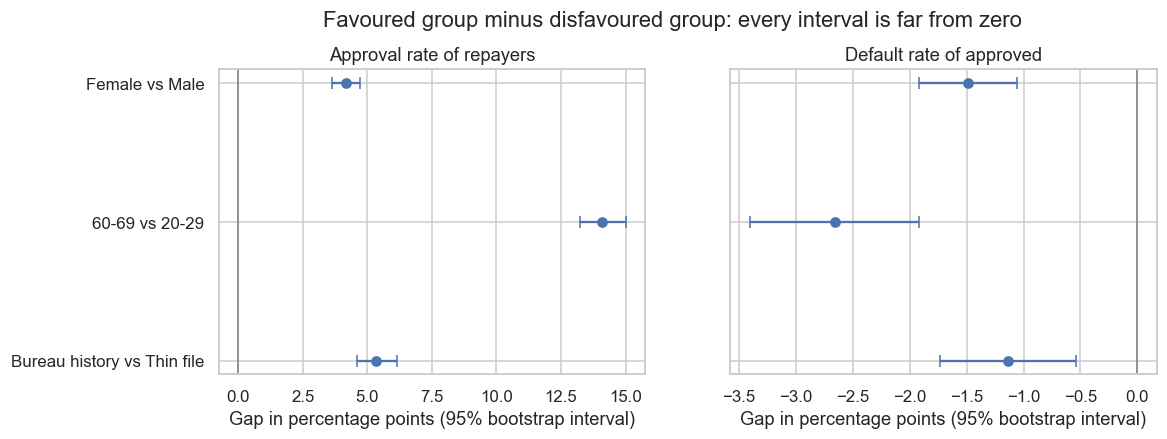

In [6]:
eo = gaps[gaps["Metric"].isin(["Approval rate of repayers", "Default rate of approved"])].copy()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, (metric, d) in zip(axes, eo.groupby("Metric", sort=False)):
    y = np.arange(len(d))[::-1]
    ax.errorbar(d["Gap"] * 100, y, xerr=[(d["Gap"] - d["95% CI low"]) * 100, (d["95% CI high"] - d["Gap"]) * 100],
                fmt="o", color="#4C72B0", capsize=4)
    ax.axvline(0, color="grey", lw=1)
    ax.set(yticks=y, yticklabels=d["Comparison"], xlabel="Gap in percentage points (95% bootstrap interval)", title=metric)
fig.suptitle("Favoured group minus disfavoured group: every interval is far from zero", y=1.03)
save(fig, "29_fairness_gaps")
plt.show()

The left panel is the equal-opportunity gap SecondLook cares about; the right panel shows that the favoured groups also get the safer approved loans.

## 6. Calibration by group

A calibrated model's predicted default rate matches the real one. If a group sat above the diagonal line, the model would be understating its risk; below it, overstating it (and wrongly declining its members).

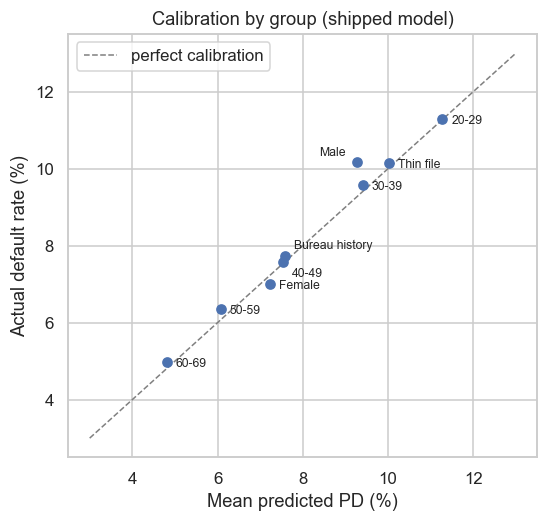

Largest calibration gap: 0.88%


In [7]:
rows = []
for g, t in tables.items():
    rows += [{"group": f"{g}: {k}", "Predicted": r["Mean predicted PD"], "Actual": r["Default rate"]} for k, r in t.iterrows()]
cal = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot([3, 13], [3, 13], color="grey", ls="--", lw=1, label="perfect calibration")
OFFSET = {"Male": (-8, 4, "right"), "Bureau history": (6, 5, "left"), "40-49": (6, -10, "left")}
ax.scatter(cal["Predicted"] * 100, cal["Actual"] * 100, color="#4C72B0", zorder=3)
for _, r in cal.iterrows():
    name = r["group"].split(": ")[1]
    dx, dy, ha = OFFSET.get(name, (6, -3, "left"))
    ax.annotate(name, (r["Predicted"] * 100, r["Actual"] * 100), xytext=(dx, dy), textcoords="offset points", fontsize=8, ha=ha)
ax.set(xlabel="Mean predicted PD (%)", ylabel="Actual default rate (%)", title="Calibration by group (shipped model)")
ax.legend(loc="upper left")
save(fig, "30_calibration_by_group")
plt.show()
print(f"Largest calibration gap: {cal.assign(gap=cal['Predicted'] - cal['Actual']).set_index('group')['gap'].abs().max():.2%}")

Every group sits on the diagonal. The shipped model's PDs mean the same thing for every gender, age band and credit file, which is what lets one cutoff be applied to everyone.

## 7. Fix experiment: retrain without the sensitive features

The obvious fix is "fairness through unawareness": remove the sensitive traits and let the model decide without them. We retrained LightGBM **without** `AGE_YEARS`, `EMPLOYED_TO_AGE` (job tenure relative to age), `NAME_FAMILY_STATUS`, `CNT_CHILDREN` and `CNT_FAM_MEMBERS`, with the same split, settings and tree-count rule as notebook 03 (5-fold CV, trees = mean best round × 1.1). Training takes about 2 to 3 minutes, so it was run once with `F.retrain_without(load_features())` and saved.

In [8]:
alt, info = F.load_no_sensitive()        # trained by F.retrain_without(load_features()): ~10 minutes, so saved
print(f"Dropped: {', '.join(info['dropped'])}")
print(f"Features: {info['n_features']} (shipped: {len(meta['features'])})   trees: {info['n_trees']} (shipped: {meta['n_trees']})")
print(f"CV AUC: {info['cv_auc_mean']:.4f} ± {info['cv_auc_std']:.4f}   (shipped: {meta['metrics']['cv_auc_mean']:.4f} ± {meta['metrics']['cv_auc_std']:.4f})")
df = df.merge(alt, on="SK_ID_CURR", how="left", validate="1:1")
assert df["PD_NO_SENSITIVE"].notna().all(), "test applicants differ between the two models"
alt_cut = F.best_cutoff(df["TARGET"], df["PD_NO_SENSITIVE"], df["AMT_CREDIT"])
print(f"Profit-maximising cutoff of the new model: {alt_cut}")

Dropped: AGE_YEARS, EMPLOYED_TO_AGE, NAME_FAMILY_STATUS, CNT_CHILDREN, CNT_FAM_MEMBERS
Features: 153 (shipped: 158)   trees: 959 (shipped: 1211)
CV AUC: 0.7820 ± 0.0024   (shipped: 0.7839 ± 0.0019)
Profit-maximising cutoff of the new model: 0.2


In [9]:
def compare(pd_col, cutoff):
    s = F.model_summary(df["TARGET"], df[pd_col], df["AMT_CREDIT"], cutoff)
    for g in GROUPINGS:
        b = F.bootstrap_gaps(df, g, pd_col=pd_col, cutoff=cutoff, n_boot=1000, pair=F.gap_pair(tables[g])).set_index("Metric")
        for m in ["Approval rate of repayers", "Four-fifths ratio"]:
            s[f"{g}: {m}" + ("" if "ratio" in m else " gap")] = b.loc[m, "Gap"]
            s[f"{g}: {m} CI"] = (b.loc[m, "95% CI low"], b.loc[m, "95% CI high"])
    return s

models = {f"Shipped, cutoff {CUTOFF}": compare("PD_LGBM", CUTOFF),
          f"Without sensitive, cutoff {CUTOFF}": compare("PD_NO_SENSITIVE", CUTOFF),
          f"Without sensitive, cutoff {alt_cut} (its best)": compare("PD_NO_SENSITIVE", alt_cut),
          f"Shipped, cutoff {alt_cut} (reference)": compare("PD_LGBM", alt_cut)}
cmp = pd.DataFrame(models)

def cell(row, v):
    if row.endswith(" CI"):
        return f"{v[0]:.3f} to {v[1]:.3f}" if "ratio" in row else f"{v[0] * 100:+.1f} to {v[1] * 100:+.1f} pts"
    if "ratio" in row or row in ("ROC AUC", "Brier score", "Cutoff"):
        return f"{v:.4f}" if row in ("ROC AUC", "Brier score") else f"{v:.2f}" if row == "Cutoff" else f"{v:.3f}"
    if row.endswith("gap"):
        return f"{v * 100:+.1f} pts"
    if row == "Good borrowers declined":
        return f"{v:,}"
    if row == "Profit (billions)":
        return f"{v:.3f}"
    return f"{v:.1%}"

cmp.apply(lambda col: [cell(r, v) for r, v in col.items()])

,"Shipped, cutoff 0.17","Without sensitive, cutoff 0.17","Without sensitive, cutoff 0.2 (its best)","Shipped, cutoff 0.2 (reference)"
ROC AUC,0.7864,0.7849,0.7849,0.7864
Brier score,0.0657,0.0657,0.0657,0.0657
Cutoff,0.17,0.17,0.20,0.20
Approval rate,88.2%,88.1%,91.0%,91.0%
Default rate of approved,5.3%,5.3%,5.7%,5.8%
Good borrowers declined,"5,181","5,236","3,795","3,786"
Profit (billions),3.679,3.673,3.686,3.673
Gender: Approval rate of repayers gap,+4.2 pts,+4.2 pts,+3.4 pts,+3.1 pts
Gender: Approval rate of repayers CI,+3.6 to +4.7 pts,+3.7 to +4.8 pts,+2.9 to +3.9 pts,+2.7 to +3.6 pts
Gender: Four-fifths ratio,0.937,0.936,0.949,0.951


**How to read this table:** the first two columns compare the models at the same cutoff, the fairest like-for-like test. The new model's profit-maximising cutoff on the test set is 0.20, so the third column shows it there, and the fourth column shows the **shipped model at that same cutoff** so we don't mistake the effect of a looser cutoff for the effect of removing features.

- **Accuracy drops slightly:** test AUC 0.7864 → 0.7849 (CV AUC 0.7839 → 0.7820). At the shipped cutoff, 55 more good borrowers are declined (5,181 → 5,236).
- **Profit is a wash.** The new model earns 0.005 billion less at 0.17 and 0.013 billion more at 0.20. Both differences are under 0.4% of profit, and the profit curves are flat around their peaks, so neither model wins on profit.
- **The age gap gets worse, not better.** At the same cutoff the equal-opportunity gap for age widens from **+14.1 to +16.3 points**, and the youngest band's four-fifths ratio falls from 0.82 to **0.80, below the line** (interval 0.79 to 0.81). The intervals don't overlap, so the widening is real.
- **Gender and thin-file gaps barely move** (within about half a point).
- **A looser cutoff narrows every gap, for both models.** At 0.20 the new model's age ratio is 0.84, but the shipped model at 0.20 reaches 0.86. Approving more people helps the disfavoured groups most (the default rate of approved loans rises from 5.3% to 5.8%), but that's a business decision about risk appetite, not a reason to drop features. The new model does narrow the thin-file gap slightly more than the shipped one at the same cutoff, but by under half a point.

In [10]:
t_alt = {g: F.group_table(df, g, pd_col="PD_NO_SENSITIVE", cutoff=CUTOFF) for g in GROUPINGS}
age = pd.DataFrame({
    "Actual default rate": tables["Age band"]["Default rate"],
    "Mean PD, shipped": tables["Age band"]["Mean predicted PD"],
    "Mean PD, without sensitive": t_alt["Age band"]["Mean predicted PD"],
    "Approval rate, shipped": tables["Age band"]["Approval rate"],
    "Approval rate, without sensitive": t_alt["Age band"]["Approval rate"],
    "Default rate of approved, shipped": tables["Age band"]["Default rate of approved"],
    "Default rate of approved, without sensitive": t_alt["Age band"]["Default rate of approved"],
})
age["Calibration gap, without sensitive"] = age["Mean PD, without sensitive"] - age["Actual default rate"]
age.style.format("{:.1%}").format("{:+.1%}", subset=["Calibration gap, without sensitive"])

,Actual default rate,"Mean PD, shipped","Mean PD, without sensitive","Approval rate, shipped","Approval rate, without sensitive","Default rate of approved, shipped","Default rate of approved, without sensitive","Calibration gap, without sensitive"
Age band,,,,,,,,
20-29,11.3%,11.3%,11.9%,79.2%,77.0%,6.9%,6.6%,+0.6%
30-39,9.6%,9.4%,9.1%,84.2%,85.2%,5.9%,6.0%,-0.5%
40-49,7.6%,7.5%,7.4%,89.3%,89.7%,5.0%,5.1%,-0.2%
50-59,6.3%,6.1%,6.4%,93.3%,92.7%,4.8%,4.7%,+0.0%
60-69,5.0%,4.8%,4.8%,96.4%,96.6%,4.2%,4.1%,-0.2%


**Why removing age backfires:** without age, the model still sees features that go with being young: short job tenure, a recently issued ID, a recent phone change, a short credit history. It can no longer tell "short tenure *for a 24-year-old*" (normal) from "short tenure for a 45-year-old" (a warning sign), so it treats youth itself as risk. Mean predicted PD for 20-29 year olds rises **above** their real default rate (11.9% predicted vs 11.3% actual), and they are approved less often. Knowing the applicant's age lets the model judge their other features in context. This is a known result in the fairness literature: removing a protected attribute doesn't remove the information, it only removes the model's ability to account for it.

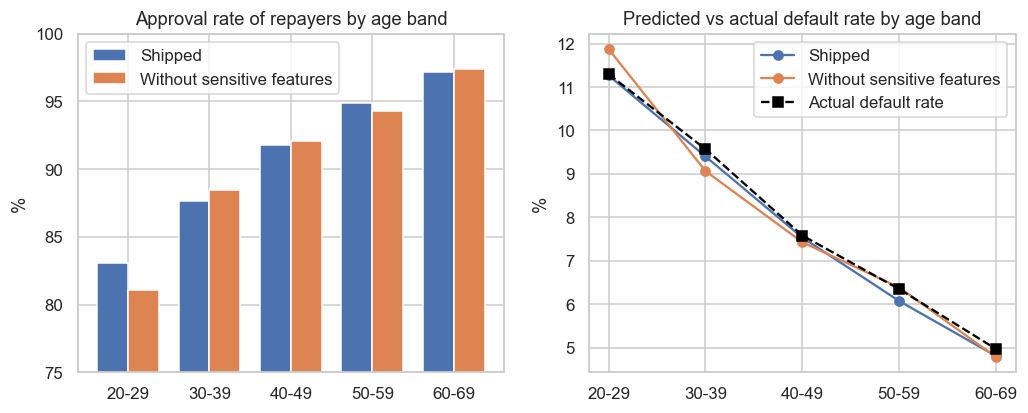

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
x = np.arange(len(age))
for i, (col, lab) in enumerate([("shipped", "Shipped"), ("without sensitive", "Without sensitive features")]):
    repayers = (tables if col == "shipped" else t_alt)["Age band"]["Approval rate of repayers"]
    axes[0].bar(x + (i - 0.5) * 0.38, repayers * 100, 0.38, label=lab)
    axes[1].plot(age.index, age[f"Mean PD, {col}"] * 100, marker="o", label=lab)
axes[0].set(xticks=x, xticklabels=age.index, ylim=(75, 100), ylabel="%", title="Approval rate of repayers by age band")
axes[1].plot(age.index, age["Actual default rate"] * 100, color="black", ls="--", marker="s", label="Actual default rate")
axes[1].set(ylabel="%", title="Predicted vs actual default rate by age band")
axes[0].legend(loc="upper left"); axes[1].legend()
save(fig, "31_fix_experiment_age")
plt.show()

## 8. Decision: which model ships

**We keep the shipped model (with all features).** Removing the sensitive features lowered accuracy, made no real difference to profit, barely moved the gender and thin-file gaps, and *widened* the age gap until the youngest band failed the four-fifths check, because the model began to overstate young applicants' risk. The shipped model is calibrated in every group, and its remaining equal-opportunity gaps are handled by design rather than by the model:

1. **Sensitive traits are never reasons.** Age, family status and children can affect the score, but SHAP labels them as sensitive and the letters never cite them (Steps 5 and 6).
2. **A human second look at the border.** Applicants in the 0.17-0.22 band are flagged *under review*, not auto-declined. The disfavoured groups are over-represented there: ages 20-29 are 25% of the under-review band vs 15% of all applicants, thin files 21% vs 14%, and men 43% vs 34%. That is where a loan officer's judgement matters most.
3. **A path to approval.** Declined applicants get the smallest loan change that would be approved (Step 8), so a gap in approval is not a dead end.
4. **Monitoring.** These tables should be re-run on new applicants, because a gap that is fair today can drift.

Because the shipped model stays, the demo bundle, letters and app numbers do not need to be rebuilt.

## 9. Save the results for the app

The Model Card page reads these numbers from `app/demo_data/fairness.json`, so the app shows the same tables, intervals and experiment as this notebook without re-running the bootstrap.

In [12]:
def records(t):
    return t.reset_index().rename(columns={t.index.name: "Group"}).replace({np.nan: None}).to_dict("records")

out = {
    "cutoff": CUTOFF, "n_test": len(df), "n_boot": 1000,
    "tables": {g: records(t.drop(columns=["Below 0.8"])) for g, t in tables.items()},
    "gaps": gaps.to_dict("records"),
    "experiment": {"dropped": info["dropped"], "alt_cutoff": alt_cut, "cv_auc": info["cv_auc_mean"],
                   "models": {k: {r: (list(v) if isinstance(v, tuple) else v) for r, v in m.items()} for k, m in models.items()},
                   "age": age.reset_index().rename(columns={"Age band": "Group"}).to_dict("records")},
}
path = ROOT / "app" / "demo_data" / "fairness.json"
path.write_text(json.dumps(out, indent=1, default=float))
print(f"Saved {path.relative_to(ROOT)} ({path.stat().st_size / 1e3:.0f} KB)")

Saved app\demo_data\fairness.json (15 KB)


## 10. Summary and limitations

**Answer:** the shipped model treats equal risk equally (calibrated in every group) and passes the four-fifths check for gender, age and credit file. It does **not** give good borrowers equal approval rates: young, male and thin-file repayers are declined more often, and all of those gaps are statistically real (the largest: 14.1 points between repayers aged 60-69 and 20-29). Removing the sensitive features made the age gap worse, so the shipped model stays, with the human review band, sensitive-trait-free explanations and the path to approval as the safeguards.

**Limitations**
- **Historical labels.** We only know outcomes for loans Home Credit actually granted. People who were declined in the past aren't in the data, so the true repayment ability of rejected groups is unknown (*selective labels*).
- **One test split.** The intervals cover sampling noise in the test set, not a different market or time. The data's country is not disclosed; a Philippine deployment would need its own audit.
- **Only three groupings, and no intersections.** Young men with thin files could face a larger gap than any single grouping shows. Income, region and education were not audited as groups.
- **One fix tried.** Other approaches (group-specific cutoffs, fairness constraints during training, reweighting) can close the gap further, but group-specific cutoffs treat applicants differently by a protected trait, which raises its own legal and ethical problems.
- **The four-fifths rule is a rule of thumb**, not a legal standard for lending in the Philippines.